# Prática 2 — Leitura de Hidrômetros com CNNs
**Disciplina:** Visão Computacional (VC001) — CESAR School, 2026.2
**Integrantes:** Thiago Alves Macena · Henrique Bouwman · Alana Cavalcanti · Manuel Galvão

Classificação de dígitos (10 classes) de hidrômetros do dataset *Yandex.Toloka Water Meters* com
`smallcnn` (do zero), **AlexNet**, **VGG16-BN** e **ResNet18** (pré-treinadas no ImageNet), sob um protocolo único.

> **Licença CC BY-NC-ND 4.0.** Imagens do dataset, recortes e checkpoints **não são versionados**.
> As células marcadas com `dataset-images` exibem imagens do dataset e têm a saída limpa antes do commit
> (`tools/clean_notebook.py`). As respostas às questões estão no `README.md`.

**Sumário:** 0 Setup · 1 Aquisição · 2 Exploração · 3 Dataset de dígitos · 4 Treino · 5 Avaliação · 6 Material para análise de erros · 7 Declaração de uso de IA

## 0. Setup e reprodutibilidade

In [1]:
import sys, os, platform, warnings, time, ast, re, collections
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2, torch
import torchvision, sklearn
from sklearn.metrics import f1_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore")
sys.path.insert(0, "src")
import data_pipeline as dp
import train_lib as T

ROOT = Path(".").resolve()
DATA, RAW = ROOT / "data", ROOT / "data" / "WaterMeters"
DIGITS, CKPT, FIG, LOCAL = ROOT / "digits", ROOT / "checkpoints", ROOT / "figures", ROOT / "local_outputs"
for p in (FIG, LOCAL, CKPT):
    p.mkdir(exist_ok=True)

T.seed_everything()
device = T.get_device()
print(f"python {platform.python_version()} | torch {torch.__version__} | torchvision {torchvision.__version__} | "
      f"sklearn {sklearn.__version__} | opencv {cv2.__version__}")
print(f"device: {device} | máquina: {platform.platform()} | CPU threads: {torch.get_num_threads()}")
FORCE_RETRAIN = False  # True ignora checkpoints/history existentes e treina tudo de novo

python 3.14.7 | torch 2.14.1 | torchvision 0.29.1 | sklearn 1.9.1 | opencv 5.0.0
device: mps | máquina: macOS-15.7.4-arm64-arm-64bit-Mach-O | CPU threads: 4


## 1. Aquisição dos dados (Parte 1)
O dataset vem do Kaggle (`tapakah68/yandextoloka-water-meters-dataset`). A célula usa, nesta ordem:
(1) a pasta `data/WaterMeters` já existente; (2) o `archive.zip` baixado do Kaggle (mesmo conteúdo); (3) a API do Kaggle
via `kagglehub` (requer `~/.kaggle/kaggle.json`). Em seguida verifica a integridade.

In [2]:
def acquire():
    if (RAW / "data.csv").exists():
        return "pasta data/WaterMeters já existente"
    for z in (ROOT / "archive.zip", ROOT.parent / "archive.zip"):
        if z.exists():
            dp.extract_zip_if_needed(z, DATA)
            return f"extraído de {z.name}"
    import kagglehub, shutil
    src = Path(kagglehub.dataset_download("tapakah68/yandextoloka-water-meters-dataset"))
    src = next(src.rglob("data.csv")).parent
    shutil.copytree(src, RAW)
    return "baixado via API do Kaggle (kagglehub)"

print("Fonte:", acquire())
report = dp.check_integrity(RAW)
print(pd.Series(report).to_string())
assert report["ok"], "download corrompido ou incompleto"
print("\nPastas:", sorted(p.name for p in RAW.iterdir()))
data = pd.read_csv(RAW / "data.csv")
print(data.dtypes.to_string())
data.head(3)

Fonte: pasta data/WaterMeters já existente


n_rows_csv                    1244
n_images                      1244
csv_sem_arquivo_em_images        0
arquivo_sem_csv_em_images        0
n_masks                       1244
csv_sem_arquivo_em_masks         0
arquivo_sem_csv_em_masks         0
n_collage                     1244
csv_sem_arquivo_em_collage       0
arquivo_sem_csv_em_collage       0
photo_name_duplicado             0
imagens_ilegiveis                0
ok                            True

Pastas: ['.DS_Store', 'collage', 'data.csv', 'images', 'masks']
photo_name        str
value         float64
location          str


,photo_name,value,location
0,id_53_value_595_825.jpg,595.825,"{'type': 'polygon', 'data': [{'x': 0.30788, 'y..."
1,id_553_value_65_475.jpg,65.475,"{'type': 'polygon', 'data': [{'x': 0.26133, 'y..."
2,id_407_value_21_86.jpg,21.860,"{'type': 'polygon', 'data': [{'x': 0.27545, 'y..."


## 2. Exploração (Parte 2)

In [3]:
# Tamanhos e orientação das fotos; formato dos polígonos
from PIL import Image
sizes = collections.Counter(Image.open(RAW / "images" / n).size for n in data.photo_name)
print(f"tamanhos (w,h): {len(sizes)} tamanhos distintos; mais comuns:", dict(sizes.most_common(5)))
print("fotos em retrato (h>w):", sum(n for (w, h), n in sizes.items() if h > w), "| paisagem (w>h):", sum(n for (w, h), n in sizes.items() if w > h), "| quadradas:", sum(n for (w, h), n in sizes.items() if w == h))
npts = collections.Counter(len(ast.literal_eval(l)["data"]) for l in data.location)
print("vértices por polígono:", dict(sorted(npts.items())))
print("polygon type:", {ast.literal_eval(l)["type"] for l in data.location})

# O rótulo do nome do arquivo vs. a coluna `value`
parsed = data.photo_name.map(lambda n: dp.parse_name(n))
data["file_value"] = [float(f"{ip}.{dp_}") for _, ip, dp_ in parsed]
data["n_int"] = [len(ip) for _, ip, _ in parsed]
data["n_dec"] = [len(dp_) for _, _, dp_ in parsed]
mism = (data.value - data.file_value).abs() > 1e-6
raw_value = pd.read_csv(RAW / "data.csv", dtype={"value": str}).value  # string original do CSV
artifact = raw_value.str.partition(".")[2].str.len() > 3
print(f"\nvalue (csv) != valor do nome do arquivo: {mism.sum()} de {len(data)}")
print(f"value (csv) com mais de 3 casas decimais na string (ruído de ponto flutuante, ex.: {raw_value[artifact].iloc[1]!r}): {artifact.sum()} de {len(data)} "
      f"(inclui 1 leitura legítima com 4 decimais)")
print("(n_int, n_dec) -> imagens:", dict(sorted(collections.Counter(zip(data.n_int, data.n_dec)).items())))

tamanhos (w,h): 38 tamanhos distintos; mais comuns: {(1000, 1333): 716, (1333, 1000): 346, (1778, 1000): 61, (1000, 1778): 24, (2057, 1000): 16}
fotos em retrato (h>w): 776 | paisagem (w>h): 456 | quadradas: 12
vértices por polígono: {4: 505, 6: 508, 8: 231}
polygon type: {'polygon'}

value (csv) != valor do nome do arquivo: 0 de 1244
value (csv) com mais de 3 casas decimais na string (ruído de ponto flutuante, ex.: '78.67699999999999'): 301 de 1244 (inclui 1 leitura legítima com 4 decimais)
(n_int, n_dec) -> imagens: {(1, 1): 3, (1, 2): 2, (1, 3): 42, (2, 1): 4, (2, 2): 23, (2, 3): 301, (2, 4): 1, (3, 1): 29, (3, 2): 59, (3, 3): 729, (4, 1): 5, (4, 2): 1, (4, 3): 42, (5, 2): 2, (5, 3): 1}


In [4]:
# A máscara traz o rótulo? Compara máscara binária x polígono `location` (IoU) em uma amostra
ious = []
for r in data.sample(150, random_state=0).itertuples():
    m = cv2.imread(str(RAW / "masks" / r.photo_name), cv2.IMREAD_GRAYSCALE)
    h, w = m.shape
    poly = np.zeros_like(m)
    cv2.fillPoly(poly, [dp.polygon_px(r.location, w, h).astype(np.int32)], 255)
    a, b = m > 127, poly > 127
    ious.append((a & b).sum() / max((a | b).sum(), 1))
print(f"IoU máscara x polígono (150 imagens): média {np.mean(ious):.3f}, mín {np.min(ious):.3f}, "
      f"{np.mean(np.array(ious) > 0.9):.0%} com IoU > 0,9")

IoU máscara x polígono (150 imagens): média 1.000, mín 0.999, 100% com IoU > 0,9


In [ ]:
# Amostra: imagem, máscara e collage (exibe imagens do dataset -> saída limpa no commit)
fig, ax = plt.subplots(3, 4, figsize=(14, 10))
for j, r in enumerate(data.sample(4, random_state=3).itertuples()):
    for i, sub in enumerate(("images", "masks", "collage")):
        ax[i, j].imshow(cv2.cvtColor(cv2.imread(str(RAW / sub / r.photo_name)), cv2.COLOR_BGR2RGB))
        ax[i, j].set_title(f"{sub} | {r.value}", fontsize=9); ax[i, j].axis("off")
plt.tight_layout(); plt.savefig(LOCAL / "eda_samples.png", dpi=80); plt.show()

rótulos válidos (5+3): 1243 | descartados: ['id_664_value_45_2676.jpg']
frequência global por dígito: {0: np.int64(3549), 1: np.int64(1003), 2: np.int64(777), 3: np.int64(779), 4: np.int64(698), 5: np.int64(677), 6: np.int64(638), 7: np.int64(620), 8: np.int64(613), 9: np.int64(590)} 
% do dígito 0: 35.7%

% de cada dígito por posição (linhas = posição 0..7):
       0      1      2      3      4      5      6      7      8      9
0  0.998  0.001  0.000  0.000  0.001  0.000  0.000  0.000  0.000  0.001
1  0.959  0.033  0.006  0.000  0.000  0.001  0.001  0.000  0.000  0.001
2  0.316  0.227  0.142  0.101  0.065  0.047  0.039  0.031  0.018  0.014
3  0.117  0.107  0.105  0.113  0.109  0.099  0.099  0.085  0.074  0.091
4  0.104  0.108  0.096  0.107  0.083  0.104  0.090  0.091  0.111  0.107
5  0.124  0.108  0.093  0.112  0.113  0.097  0.093  0.085  0.104  0.072
6  0.134  0.109  0.090  0.094  0.087  0.101  0.097  0.101  0.102  0.085
7  0.103  0.115  0.095  0.099  0.104  0.096  0.096  0.105  0.0

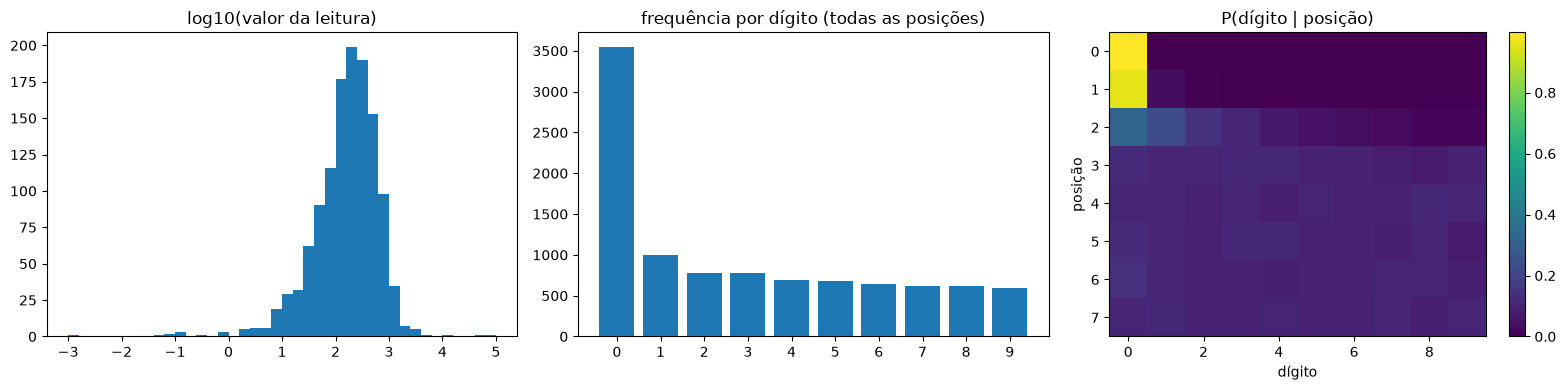

In [6]:
# Distribuição das leituras e dos dígitos (classe majoritária)
labels = {n: dp.label_8_digits(n) for n in data.photo_name}
valid = {n: l for n, l in labels.items() if l is not None}
digit_mat = np.array([[int(c) for c in l] for l in valid.values()])
counts = np.bincount(digit_mat.ravel(), minlength=10)
print("rótulos válidos (5+3):", len(valid), "| descartados:", [n for n, l in labels.items() if l is None])
print("frequência global por dígito:", dict(enumerate(counts)), "\n% do dígito 0:", f"{counts[0] / counts.sum():.1%}")
by_pos = np.stack([np.bincount(digit_mat[:, p], minlength=10) for p in range(8)]) / len(valid)
print("\n% de cada dígito por posição (linhas = posição 0..7):")
print(pd.DataFrame(by_pos, columns=range(10)).round(3).to_string())
print("\nlabels com decimais '000':", sum(l[5:] == "000" for l in valid.values()),
      f"({np.mean([l[5:] == '000' for l in valid.values()]):.1%}); esperado ao acaso ~0,1%")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(np.log10(data.value.clip(lower=0.001)), bins=40); ax[0].set_title("log10(valor da leitura)")
ax[1].bar(range(10), counts); ax[1].set_title("frequência por dígito (todas as posições)"); ax[1].set_xticks(range(10))
im = ax[2].imshow(by_pos, aspect="auto", cmap="viridis"); ax[2].set_title("P(dígito | posição)")
ax[2].set_xlabel("dígito"); ax[2].set_ylabel("posição"); plt.colorbar(im, ax=ax[2])
plt.tight_layout(); plt.show()

## 3. Construção do dataset de dígitos (Parte 3)
Pipeline: polígono `location` → faixa retificada **384×64** (perspectiva para polígonos de 4 pontos; retângulo de área mínima para os de 6/8) →
**correção de orientação** → 8 recortes **48×64** → separação conforme o `splits.csv` oficial.

**Orientação.** O eixo longo do polígono define a direção de leitura (visores verticais são girados 90°). Para resolver a ambiguidade
0°/180° usa-se a cor: os 3 dígitos decimais são vermelhos, então a faixa é girada 180° se houver mais vermelho (percentil 95 de `R−max(G,B)`)
nos 3 primeiros recortes do que nos 3 últimos (só na banda central da faixa, para ignorar molduras). Se a diferença for < 8 não há evidência
de cor e **nada é corrigido** (`orient_ok=False`); essas faixas são contadas abaixo.

In [7]:
index, strips_info, summ = dp.build_digit_dataset(RAW, ROOT / "splits.csv", DIGITS, LOCAL / "strips")
print({k: v for k, v in summ.items()})
assert summ["n_valid"] == 1243 and summ["n_discarded"] == 1 and summ["n_crops"] == 9944 and summ["leakage"] == 0
splits_off = pd.read_csv(ROOT / "splits.csv")
assert set(strips_info.photo_name) == set(splits_off.photo_name), "imagens diferentes do splits.csv oficial"
assert (index.groupby("photo_name").split.nunique() == 1).all(), "vazamento entre splits!"
print("\nimagens por split:", strips_info.split.value_counts().to_dict())
print("recortes por split:", index.split.value_counts().to_dict())
print("colunas de digits/index.csv:", list(index.columns))

{'n_valid': 1243, 'n_discarded': 1, 'discarded': [('id_664_value_45_2676.jpg', 'formato fora de 5+3')], 'n_crops': 9944, 'n_vertical': 105, 'n_flipped': 138, 'n_corrected': 198, 'n_orient_undecided': 73, 'leakage': 0}

imagens por split: {'train': 870, 'test': 187, 'val': 186}
recortes por split: {'train': 6960, 'test': 1496, 'val': 1488}
colunas de digits/index.csv: ['image_id', 'photo_name', 'position', 'digit', 'split', 'crop_path']


In [8]:
# Correções de orientação e qualidade geométrica
si = strips_info
print(f"faixas com visor vertical (giradas 90°): {si.vertical.sum()}")
print(f"faixas giradas 180° (vermelho à esquerda): {si.flipped.sum()}")
print(f"faixas corrigidas no total (90° e/ou 180°): {(si.vertical | si.flipped).sum()}")
print(f"faixas sem evidência de cor (orientação não verificável): {(~si.orient_ok).sum()} "
      f"({(~si.orient_ok).mean():.1%}) — das quais verticais: {(~si.orient_ok & si.vertical).sum()}")
print("\nrazão de aspecto do polígono (alvo da faixa = 384/64 = 6,0):")
print(si.aspect.describe().round(2).to_string())
print(f"fora de [4,7]: {((si.aspect < 4) | (si.aspect > 7)).sum()} | < 4: {(si.aspect < 4).sum()} | > 7: {(si.aspect > 7).sum()}")
print("\nmais de um tambor 'sem decimais' (rótulo xxxxx000): ", int((si.label.str[5:] == '000').sum()))
print("\nrecortes por dígito e split:")
print(pd.crosstab(index.digit, index.split).to_string())

faixas com visor vertical (giradas 90°): 105
faixas giradas 180° (vermelho à esquerda): 138
faixas corrigidas no total (90° e/ou 180°): 198
faixas sem evidência de cor (orientação não verificável): 73 (5.9%) — das quais verticais: 7

razão de aspecto do polígono (alvo da faixa = 384/64 = 6,0):
count    1243.00
mean        5.12
std         0.91
min         2.83
25%         4.42
50%         4.99
75%         5.63
max         8.73
fora de [4,7]: 113 | < 4: 55 | > 7: 58

mais de um tambor 'sem decimais' (rótulo xxxxx000):  36

recortes por dígito e split:
split  test  train  val
digit                  
0       515   2482  552
1       150    718  135
2       130    525  122
3       111    553  115
4       113    488   97
5        96    480  101
6       109    450   79
7        75    450   95
8       112    400  101
9        85    414   91


In [ ]:
# Amostra das faixas retificadas e dos recortes (exibe imagens do dataset -> saída limpa no commit)
samp = strips_info.sample(8, random_state=7)
fig, ax = plt.subplots(8, 9, figsize=(15, 8.5), gridspec_kw=dict(width_ratios=[4] + [0.5] * 8))
for i, r in enumerate(samp.itertuples()):
    s = cv2.cvtColor(cv2.imread(str(LOCAL / "strips" / f"{r.image_id}.png")), cv2.COLOR_BGR2RGB)
    ax[i, 0].imshow(s); ax[i, 0].set_title(f"{r.label} v={int(r.vertical)} f={int(r.flipped)}", fontsize=8); ax[i, 0].axis("off")
    for p, c in enumerate(dp.split_crops(s)):
        ax[i, p + 1].imshow(c); ax[i, p + 1].axis("off")
plt.tight_layout(); plt.savefig(LOCAL / "strips_samples.png", dpi=80); plt.show()

In [10]:
# Para a análise manual (Q3.2): 60 faixas aleatórias com o rótulo, salvas em local_outputs (não versionado)
aud = strips_info.sample(60, random_state=123)
tiles = []
for k, r in enumerate(aud.itertuples()):
    s = cv2.copyMakeBorder(cv2.imread(str(LOCAL / "strips" / f"{r.image_id}.png")), 0, 14, 0, 0, cv2.BORDER_CONSTANT, value=(255, 255, 255))
    cv2.putText(s, f"#{k} img {r.image_id} lab {r.label} ok{int(r.orient_ok)}", (2, 74), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 0, 0), 1)
    tiles.append(s)
cv2.imwrite(str(LOCAL / "audit_60_strips.png"), np.vstack([np.hstack(tiles[k:k + 3]) for k in range(0, 60, 3)]))
aud[["image_id", "label", "orient_ok", "vertical", "flipped"]].reset_index(drop=True).to_csv(LOCAL / "audit_60_strips.csv")
print("salvo em local_outputs/audit_60_strips.png (+ .csv)")

salvo em local_outputs/audit_60_strips.png (+ .csv)


## 4. Treinamento dos quatro modelos (Parte 4)
**Protocolo** (idêntico para todos; seed 42; `splits.csv` oficial): AdamW + OneCycleLR; `CrossEntropyLoss(label_smoothing=0.1)`;
1ª época com o backbone congelado (só a **cabeça** = última camada linear nova treina; BN/dropout do backbone em `eval`);
early stopping pelo F1-macro de validação (paciência 3); augmentation `RandomAffine(5°, translate 5%, scale 0,95–1,05)` + `ColorJitter(0,3; 0,3)`, sem flip;
normalização com média/desvio do ImageNet (também na `smallcnn`, por uniformidade). Entrada: `smallcnn` 64×48 (recorte nativo); demais 128×128 (redimensionamento bilinear no device).
Batches de MPS/CPU conforme o roteiro. O melhor checkpoint (maior F1-macro de validação) é o avaliado no teste.

In [11]:
tr, va, te = (index[index.split == s].reset_index(drop=True) for s in ("train", "val", "test"))
x_tr, x_va, x_te = (T.load_crops(d, ROOT) for d in (tr, va, te))
y_tr, y_va, y_te = tr.digit.values, va.digit.values, te.digit.values
print("treino/val/teste (recortes):", len(tr), len(va), len(te))
print(pd.DataFrame(T.PROTOCOL).T.to_string())

treino/val/teste (recortes): 6960 1488 1496
               input batch lr_head lr_backbone epochs pretrained
smallcnn    (64, 48)   128   0.001        None     10      False
alexnet   (128, 128)    64   0.001      0.0001      8       True
vgg16_bn  (128, 128)    16   0.001     0.00001      8       True
resnet18  (128, 128)    64   0.001      0.0001      8       True


In [12]:
history = {}
t_all = time.time()
for name in T.PROTOCOL:
    hp, ck = ROOT / f"history_{name}.csv", CKPT / f"{name}.pt"
    if hp.exists() and ck.exists() and not FORCE_RETRAIN:
        history[name] = pd.read_csv(hp); print(f"[{name}] reaproveitando history/checkpoint existentes"); continue
    h, _ = T.train_model(name, x_tr, y_tr, x_va, y_va, device, CKPT)
    h.to_csv(hp, index=False); history[name] = h
print(f"\ntempo total de treino: {(time.time() - t_all) / 60:.1f} min")

[smallcnn] reaproveitando history/checkpoint existentes
[alexnet] reaproveitando history/checkpoint existentes
[vgg16_bn] reaproveitando history/checkpoint existentes
[resnet18] reaproveitando history/checkpoint existentes

tempo total de treino: 0.0 min


## 5. Avaliação no conjunto de teste (Parte 5)
Todas as métricas abaixo usam **apenas o teste**; a validação só serviu ao early stopping.

In [13]:
preds, results, extra = {}, [], []
for name, cfg in T.PROTOCOL.items():
    model = T.load_best(name, CKPT / f"{name}.pt", device)
    te_loader = T.make_loader(x_te, y_te, False, 128, workers=0)
    lg, yy = T.predict(model, te_loader, device)
    prob = lg.softmax(1)
    conf, pred = prob.max(1)
    df = te[["image_id", "photo_name", "position", "digit"]].copy()
    df["pred"], df["conf"] = pred.numpy(), conf.numpy()
    df["correct"] = df.pred == df.digit
    df.to_csv(ROOT / f"predictions_{name}.csv", index=False)
    preds[name] = df

    h = history[name]
    n_params = T.n_params_M(model)
    ckpt_mb = os.path.getsize(CKPT / f"{name}.pt") / 1e6
    ms_dev = T.latency_ms(model, device, cfg["input"])
    model_cpu = T.load_best(name, CKPT / f"{name}.pt", torch.device("cpu"))
    ms_cpu = T.latency_ms(model_cpu, torch.device("cpu"), cfg["input"])
    gm = T.gmacs(model_cpu, cfg["input"])
    tr_pred = T.predict(model, T.make_loader(x_tr, y_tr, False, 128, workers=0), device)
    train_acc_eval = float((tr_pred[0].argmax(1).numpy() == y_tr).mean())
    results.append(dict(
        model=name, acc_digit=df.correct.mean(), f1_macro=f1_score(df.digit, df.pred, average="macro"),
        acc_reading=df.groupby("image_id").correct.all().mean(), params_M=n_params,
        s_per_epoch=h.seconds.median(), ms_per_image=ms_dev, ckpt_MB=ckpt_mb,
        best_epoch=int(h.loc[h.val_f1.idxmax(), "epoch"])))
    extra.append(dict(model=name, ms_per_image_cpu=ms_cpu, gmacs=gm, epochs_run=len(h), train_acc_eval_mode=train_acc_eval,
                      val_f1_best=h.val_f1.max(), total_train_s=h.seconds.sum()))
    print(f"[{name}] ok")

res = pd.DataFrame(results)
res_out = res.round({"acc_digit": 4, "f1_macro": 4, "acc_reading": 4, "params_M": 3, "s_per_epoch": 2, "ms_per_image": 3, "ckpt_MB": 1})
res_out.to_csv(ROOT / "results.csv", index=False)
pd.DataFrame(extra).round(4).to_csv(ROOT / "results_extra.csv", index=False)
print(f"\nms_per_image medido em: {device} (batch 1, mediana de 200 execuções após 20 de aquecimento); versão CPU em results_extra.csv")
res_out

[smallcnn] ok


[alexnet] ok


[vgg16_bn] ok


[resnet18] ok

ms_per_image medido em: mps (batch 1, mediana de 200 execuções após 20 de aquecimento); versão CPU em results_extra.csv


,model,acc_digit,f1_macro,acc_reading,params_M,s_per_epoch,ms_per_image,ckpt_MB,best_epoch
0,smallcnn,0.8951,0.8807,0.5722,0.289,4.42,0.770,1.2,10
1,alexnet,0.9178,0.8990,0.6364,57.045,18.40,3.285,228.2,8
2,vgg16_bn,0.9372,0.9284,0.7273,134.310,303.04,10.626,537.3,6
3,resnet18,0.9592,0.9547,0.8449,11.182,27.36,3.182,44.8,7


In [14]:
pd.read_csv(ROOT / "results_extra.csv")

,model,ms_per_image_cpu,gmacs,epochs_run,train_acc_eval_mode,val_f1_best,total_train_s
0,smallcnn,0.9534,0.1159,10,0.9134,0.8722,46.5863
1,alexnet,4.6924,0.2508,8,0.9797,0.9006,139.7834
2,vgg16_bn,27.7526,5.1309,8,0.9720,0.9380,2129.9587
3,resnet18,6.5275,0.5922,8,0.9958,0.9535,206.8631


In [15]:
for name, df in preds.items():
    print(f"\n===== {name} =====")
    print(classification_report(df.digit, df.pred, digits=4))


===== smallcnn =====
              precision    recall  f1-score   support

           0     0.8919    0.9612    0.9252       515
           1     0.8333    0.9000    0.8654       150
           2     0.9512    0.9000    0.9249       130
           3     0.9182    0.9099    0.9140       111
           4     0.9423    0.8673    0.9032       113
           5     0.8333    0.8854    0.8586        96
           6     0.8876    0.7248    0.7980       109
           7     0.8732    0.8267    0.8493        75
           8     0.9412    0.8571    0.8972       112
           9     0.9103    0.8353    0.8712        85

    accuracy                         0.8951      1496
   macro avg     0.8983    0.8668    0.8807      1496
weighted avg     0.8967    0.8951    0.8942      1496


===== alexnet =====
              precision    recall  f1-score   support

           0     0.9558    0.9650    0.9604       515
           1     0.9048    0.8867    0.8956       150
           2     0.9318    0.9462  

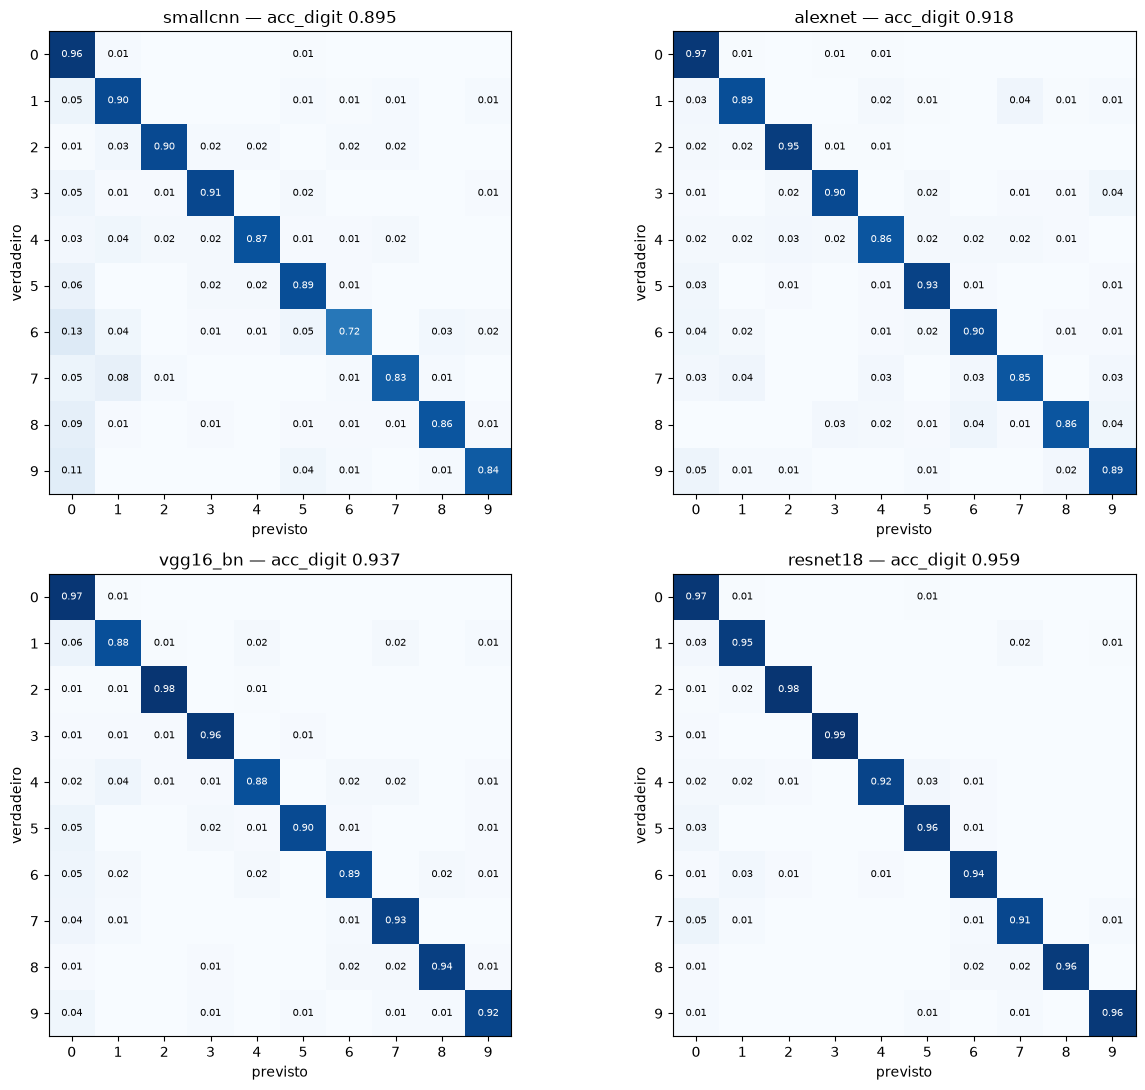

In [16]:
# Figura 1: matrizes de confusão normalizadas (por linha = classe verdadeira)
fig, ax = plt.subplots(2, 2, figsize=(13, 11))
for a, (name, df) in zip(ax.ravel(), preds.items()):
    cm = confusion_matrix(df.digit, df.pred, labels=range(10), normalize="true")
    im = a.imshow(cm, vmin=0, vmax=1, cmap="Blues")
    for i in range(10):
        for j in range(10):
            a.text(j, i, f"{cm[i, j]:.2f}" if cm[i, j] >= 0.005 else "", ha="center", va="center", fontsize=7,
                   color="white" if cm[i, j] > 0.5 else "black")
    a.set_xticks(range(10)); a.set_yticks(range(10)); a.set_xlabel("previsto"); a.set_ylabel("verdadeiro")
    a.set_title(f"{name} — acc_digit {df.correct.mean():.3f}")
plt.tight_layout(); plt.savefig(FIG / "confusion_matrices.png", dpi=130); plt.show()

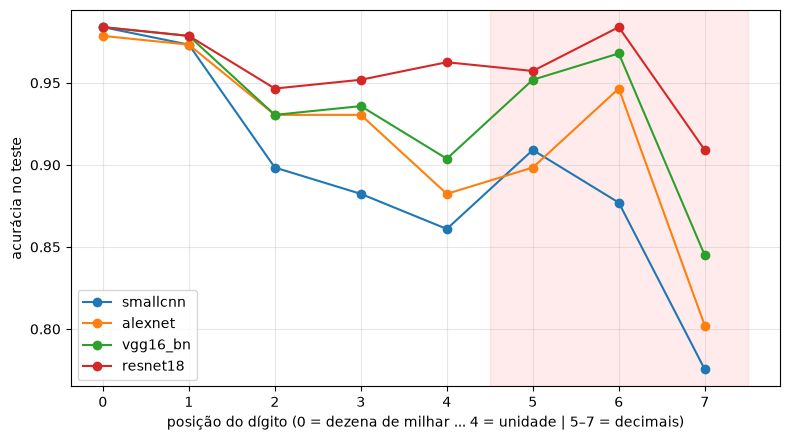

          smallcnn  alexnet  vgg16_bn  resnet18
position                                       
0           0.9840   0.9786    0.9840    0.9840
1           0.9733   0.9733    0.9786    0.9786
2           0.8984   0.9305    0.9305    0.9465
3           0.8824   0.9305    0.9358    0.9519
4           0.8610   0.8824    0.9037    0.9626
5           0.9091   0.8984    0.9519    0.9572
6           0.8770   0.9465    0.9679    0.9840
7           0.7754   0.8021    0.8449    0.9091


In [17]:
# Figura 2: acurácia por posição do dígito (0-7)
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, df in preds.items():
    acc = df.groupby("position").correct.mean()
    ax.plot(acc.index, acc.values, marker="o", label=name)
ax.set_xlabel("posição do dígito (0 = dezena de milhar ... 4 = unidade | 5–7 = decimais)"); ax.set_ylabel("acurácia no teste")
ax.axvspan(4.5, 7.5, alpha=0.08, color="red"); ax.set_xticks(range(8)); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "accuracy_by_position.png", dpi=130); plt.show()
print(pd.DataFrame({n: d.groupby("position").correct.mean() for n, d in preds.items()}).round(4).to_string())

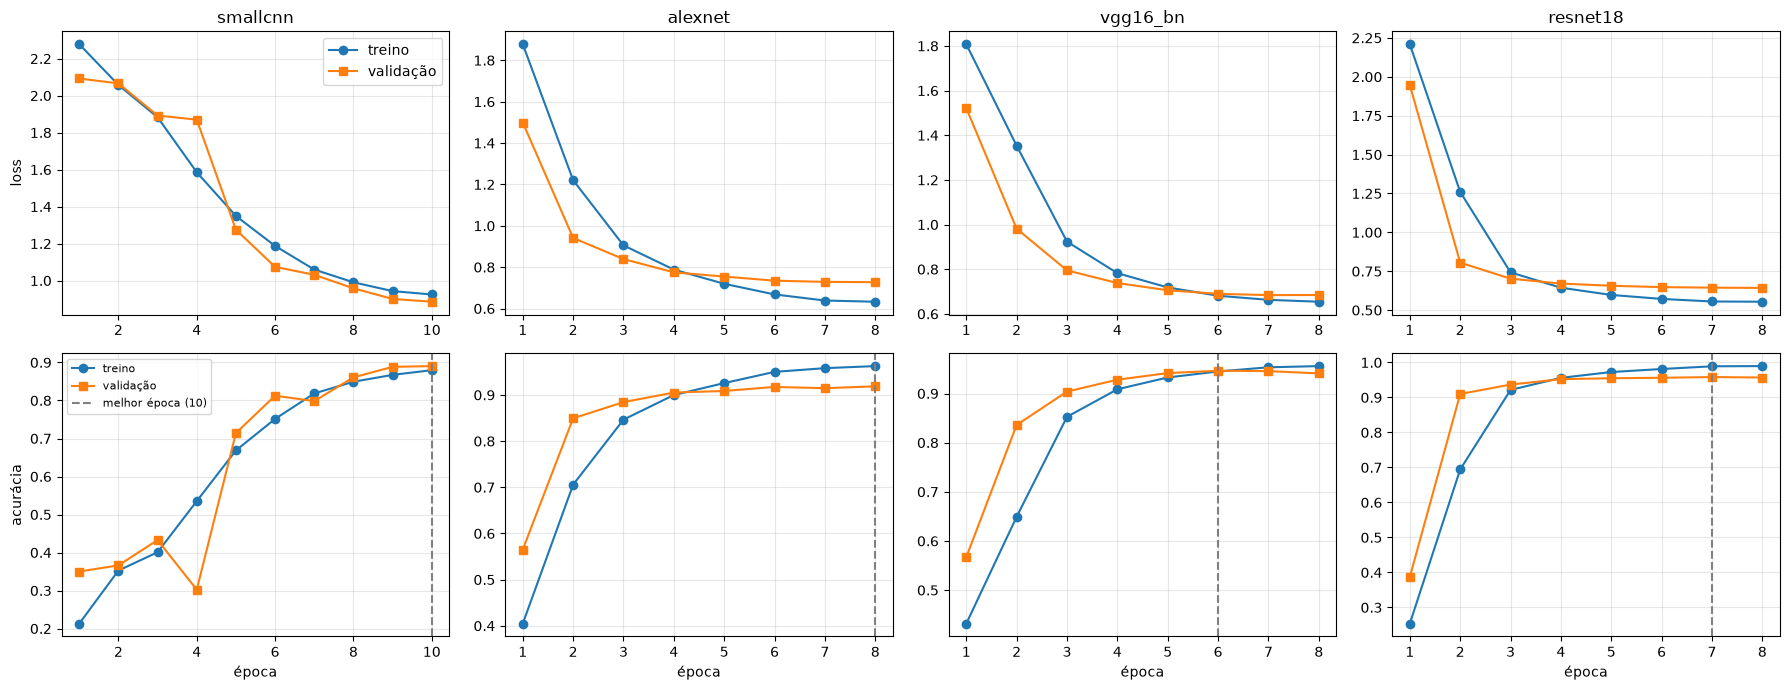

In [18]:
# Figura 3: curvas de treino (loss e acurácia, treino x validação)
fig, ax = plt.subplots(2, 4, figsize=(18, 7), sharex=False)
for j, (name, h) in enumerate(history.items()):
    ax[0, j].plot(h.epoch, h.train_loss, "o-", label="treino"); ax[0, j].plot(h.epoch, h.val_loss, "s-", label="validação")
    ax[0, j].set_title(name); ax[0, j].set_ylabel("loss" if j == 0 else ""); ax[0, j].grid(alpha=0.3)
    ax[1, j].plot(h.epoch, h.train_acc, "o-", label="treino"); ax[1, j].plot(h.epoch, h.val_acc, "s-", label="validação")
    best = h.loc[h.val_f1.idxmax(), "epoch"]; ax[1, j].axvline(best, ls="--", c="gray", label=f"melhor época ({best})")
    ax[1, j].set_xlabel("época"); ax[1, j].set_ylabel("acurácia" if j == 0 else ""); ax[1, j].grid(alpha=0.3)
ax[0, 0].legend(); ax[1, 0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "training_curves.png", dpi=130); plt.show()

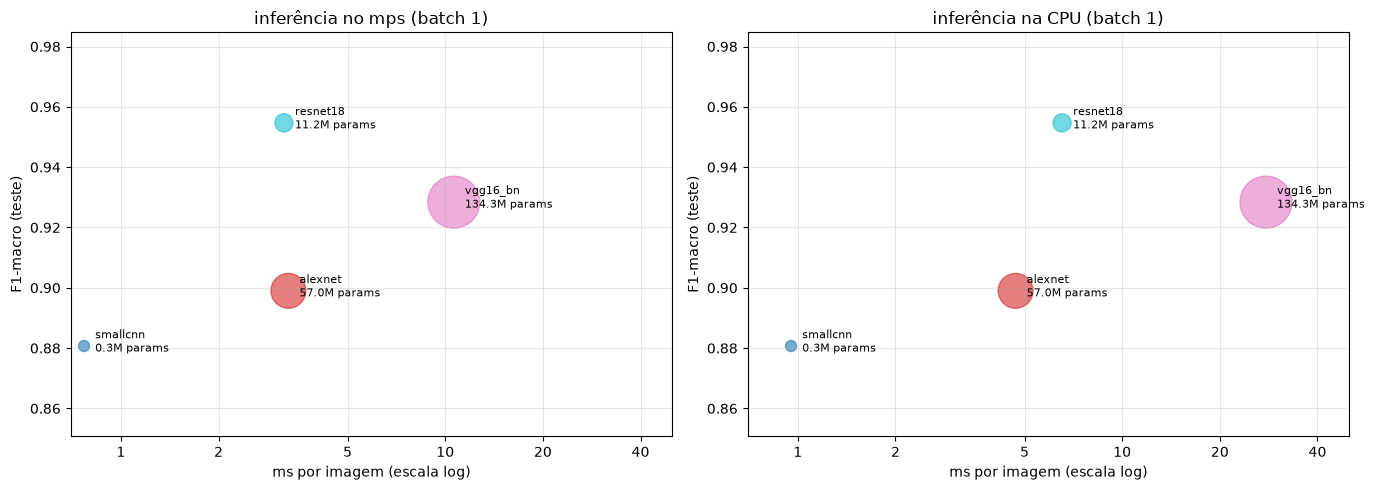

In [19]:
# Figura 4: desempenho x custo (F1-macro x tempo de inferência; área = nº de parâmetros)
ex = pd.read_csv(ROOT / "results_extra.csv")
r = res_out.merge(ex[["model", "ms_per_image_cpu"]], on="model")
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, col, ttl in ((ax[0], "ms_per_image", f"inferência no {device} (batch 1)"), (ax[1], "ms_per_image_cpu", "inferência na CPU (batch 1)")):
    a.scatter(r[col], r.f1_macro, s=60 + r.params_M * 10, alpha=0.6, c=range(4), cmap="tab10")
    for q in r.itertuples():
        a.annotate(f"{q.model}\n{q.params_M:.1f}M params", (getattr(q, col), q.f1_macro), textcoords="offset points", xytext=(8, -4), fontsize=8)
    a.set_xscale("log"); a.set_xticks([1, 2, 5, 10, 20, 40]); a.set_xticklabels(["1", "2", "5", "10", "20", "40"]); a.minorticks_off(); a.set_xlim(0.7, 50); a.set_xlabel("ms por imagem (escala log)"); a.set_ylabel("F1-macro (teste)"); a.set_title(ttl); a.grid(alpha=0.3)
    a.set_ylim(min(r.f1_macro) - 0.03, 1.0 if max(r.f1_macro) > 0.97 else max(r.f1_macro) + 0.03)
plt.tight_layout(); plt.savefig(FIG / "performance_vs_cost.png", dpi=130); plt.show()

## 6. Material para a análise de erros e limitações
Tudo aqui é **diagnóstico** (nenhuma métrica nova de avaliação): onde os modelos erram, se o erro é compartilhado
(sinal de problema de dado/rótulo/recorte) ou específico de um modelo (limitação do modelo), e quanto do erro ligado ao pipeline.

In [20]:
# 6.1 Pares de classes mais confundidos (contagem absoluta e % da classe verdadeira)
for name, df in preds.items():
    e = df[~df.correct].groupby(["digit", "pred"]).size().rename("n").reset_index()
    tot = df.groupby("digit").size()
    e["pct_da_classe"] = (e.n / e.digit.map(tot) * 100).round(1)
    print(f"\n{name}: {len(df[~df.correct])} erros em {len(df)} recortes — top 8 pares (verdadeiro → previsto)")
    print(e.sort_values("n", ascending=False).head(8).to_string(index=False))


smallcnn: 157 erros em 1496 recortes — top 8 pares (verdadeiro → previsto)
 digit  pred  n  pct_da_classe
     6     0 14           12.8
     8     0 10            8.9
     9     0  9           10.6
     1     0  8            5.3
     0     1  7            1.4
     5     0  6            6.2
     7     1  6            8.0
     6     5  5            4.6

alexnet: 123 erros em 1496 recortes — top 8 pares (verdadeiro → previsto)
 digit  pred  n  pct_da_classe
     1     7  6            4.0
     8     6  5            4.5
     0     1  4            0.8
     3     9  4            3.6
     9     0  4            4.7
     8     9  4            3.6
     6     0  4            3.7
     1     0  4            2.7

vgg16_bn: 94 erros em 1496 recortes — top 8 pares (verdadeiro → previsto)
 digit  pred  n  pct_da_classe
     1     0  9            6.0
     6     0  5            4.6
     5     0  5            5.2
     4     1  5            4.4
     7     0  3            4.0
     1     4  3            2.0

In [21]:
# 6.2 Erros por posição, nº de dígitos errados por imagem e por quanto cada modelo "perde" em acc_reading
rows = []
for name, df in preds.items():
    wrong = df.groupby("image_id").apply(lambda g: (~g.correct).sum())
    rows.append(dict(model=name, **{f"{k} erros": int((wrong == k).sum()) for k in range(4)}, **{"≥4 erros": int((wrong >= 4).sum())},
                     acc_reading=(wrong == 0).mean()))
print("distribuição de nº de dígitos errados por imagem de teste (187 imagens):")
print(pd.DataFrame(rows).round(4).to_string(index=False))
acc_d = res.set_index("model").acc_digit
print("\nacc_digit^8 (leitura esperada se erros fossem independentes e iguais em todas as posições) vs acc_reading medido:")
print(pd.DataFrame({"acc_digit^8": acc_d ** 8, "acc_reading": res.set_index("model").acc_reading}).round(4).to_string())

distribuição de nº de dígitos errados por imagem de teste (187 imagens):
   model  0 erros  1 erros  2 erros  3 erros  ≥4 erros  acc_reading
smallcnn      107       43       19        8        10       0.5722
 alexnet      119       45       10        3        10       0.6364
vgg16_bn      136       33        7        5         6       0.7273
resnet18      158       18        3        3         5       0.8449

acc_digit^8 (leitura esperada se erros fossem independentes e iguais em todas as posições) vs acc_reading medido:
          acc_digit^8  acc_reading
model                             
smallcnn       0.4119       0.5722
alexnet        0.5034       0.6364
vgg16_bn       0.5950       0.7273
resnet18       0.7167       0.8449


In [22]:
# 6.3 Erro ligado ao pipeline: grupos de imagens (todos os modelos)
meta = strips_info.set_index("image_id")
rows = []
for name, df in preds.items():
    d = df.join(meta[["orient_ok", "vertical", "flipped", "aspect", "label"]], on="image_id")
    d["sem_decimais(xxx000)"] = d.label.str[5:] == "000"
    d["aspect_fora_4_7"] = (d.aspect < 4) | (d.aspect > 7)
    for g in ["sem_decimais(xxx000)", "orient_ok", "vertical", "flipped", "aspect_fora_4_7"]:
        for v, sub in d.groupby(g):
            rows.append(dict(model=name, grupo=g, valor=v, n_recortes=len(sub), acc_digit=sub.correct.mean(),
                             acc_dec_pos5_7=sub[sub.position >= 5].correct.mean()))
g = pd.DataFrame(rows)
print(g.pivot_table(index=["grupo", "valor"], columns="model", values="acc_digit").round(3).to_string())
print("\nrecortes de teste por grupo:", g[g.model == "resnet18"].set_index(["grupo", "valor"]).n_recortes.to_dict())

model                       alexnet  resnet18  smallcnn  vgg16_bn
grupo                valor                                       
aspect_fora_4_7      False    0.922     0.960     0.898     0.939
                     True     0.838     0.938     0.838     0.900
flipped              False    0.923     0.961     0.904     0.940
                     True     0.868     0.941     0.809     0.904
orient_ok            False    0.611     0.681     0.597     0.667
                     True     0.933     0.973     0.910     0.951
sem_decimais(xxx000) False    0.928     0.969     0.906     0.947
                     True     0.438     0.531     0.406     0.500
vertical             False    0.922     0.959     0.897     0.938
                     True     0.875     0.958     0.875     0.933

recortes de teste por grupo: {('sem_decimais(xxx000)', False): 1464, ('sem_decimais(xxx000)', True): 32, ('orient_ok', False): 72, ('orient_ok', True): 1424, ('vertical', False): 1376, ('vertical', True): 12

In [23]:
# 6.4 Erros compartilhados: quantos recortes todos os modelos erram? (indício de rótulo/recorte ruim, não do modelo)
P = pd.DataFrame({n: ~d.correct.values for n, d in preds.items()})
P["k"] = P.sum(1)
print("nº de modelos que erram o recorte -> recortes:", P.k.value_counts().sort_index().to_dict())
pre = ["alexnet", "vgg16_bn", "resnet18"]
print("erram os 4:", int((P.k == 4).sum()), "| erram os 3 pré-treinados:", int((P[pre].sum(1) == 3).sum()),
      "| erro exclusivo de 1 modelo:", int((P.k == 1).sum()))
shared = te.assign(n_modelos_erram=P.k.values)
print("\nposição dos recortes errados por todos os 4:")
print(shared[shared.n_modelos_erram == 4].position.value_counts().sort_index().to_dict())
print("\nconfiança média: acertos x erros")
print(pd.DataFrame({n: {"acertos": d[d.correct].conf.mean(), "erros": d[~d.correct].conf.mean(), "erros com conf>0,9": int(((~d.correct) & (d.conf > 0.9)).sum())}
                    for n, d in preds.items()}).round(3).to_string())

nº de modelos que erram o recorte -> recortes: {0: 1277, 1: 117, 2: 34, 3: 22, 4: 46}
erram os 4: 46 | erram os 3 pré-treinados: 50 | erro exclusivo de 1 modelo: 117

posição dos recortes errados por todos os 4:
{0: 2, 1: 4, 2: 8, 3: 7, 4: 7, 5: 6, 6: 2, 7: 10}

confiança média: acertos x erros
                    smallcnn  alexnet  vgg16_bn  resnet18
acertos                0.724    0.839     0.851     0.875
erros                  0.383    0.501     0.488     0.516
erros com conf>0,9     2.000    4.000     3.000     1.000


In [24]:
# 6.5 Generalização: acurácia de treino (modo eval, sem augmentation) x validação x teste
ex = pd.read_csv(ROOT / "results_extra.csv").set_index("model")
print(pd.DataFrame({"treino": ex.train_acc_eval_mode, "val(melhor)": {n: history[n].loc[history[n].val_f1.idxmax(), "val_acc"] for n in history},
                    "teste": res.set_index("model").acc_digit}).round(4).to_string())

          treino  val(melhor)   teste
smallcnn  0.9134       0.8905  0.8951
alexnet   0.9797       0.9187  0.9178
vgg16_bn  0.9720       0.9462  0.9372
resnet18  0.9958       0.9583  0.9592


In [ ]:
# 6.6 Galeria: os 16 erros mais confiantes de cada modelo (exibe recortes do dataset -> saída limpa no commit)
def gallery(df_err, title, path):
    fig, ax = plt.subplots(2, 8, figsize=(16, 4.6))
    for a, (_, r) in zip(ax.ravel(), df_err.iterrows()):
        i = te.index[(te.image_id == r.image_id) & (te.position == r.position)][0]
        a.imshow(x_te[i].permute(1, 2, 0).numpy()); a.axis("off")
        a.set_title(f"img {r.image_id} p{r.position}\n{r.digit}→{r.pred} ({r.conf:.2f})", fontsize=8)
    for a in ax.ravel()[len(df_err):]:
        a.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.savefig(path, dpi=90); plt.show()

for name, df in preds.items():
    gallery(df[~df.correct].sort_values("conf", ascending=False).head(16), f"{name}: 16 erros mais confiantes", LOCAL / f"errors_{name}.png")

shared_err = te.assign(pred=preds["resnet18"].pred.values, conf=preds["resnet18"].conf.values)[P.k.values == 4]
gallery(shared_err.sort_values("conf", ascending=False).head(16), "errados pelos 4 modelos (pred/conf da resnet18)", LOCAL / "errors_shared_by_all.png")

## 7. Declaração de Uso de IA
Conforme a política da disciplina (VC001, 2026.2). Os campos de identificação individual (nome completo, matrícula, data)
são preenchidos por cada integrante no `README.md`.

**Utilizou IA?** Sim. **Modelo:** Claude Sonnet 5.5 (`claude-sonnet-5-5`), via Claude Code (extensão do VS Code).

**Prompt inicial enviado ao modelo (cópia literal):**
> vou realizar um trabalho pratico de visão computacional, quero que voce siga as regras do trabalho e me utilize para ter o lado critico e de entendimento teorico. na pasta ja existe oque o professor passou e aqui esta o repositorio inicial do professor: https://github.com/eron93br/vc-20262-p2
> repositorio que vamos utilizar é o: https://github.com/thiago1187/Pratica-2-Visao-Computacional.git
> meu git já esta no terminal e no read me já coloque integrantes do grupo: eu: Thiago Alves Macena (tam7@cesar.school) Henrique Bouwman (hvb@cesar.school) (Alana Cavalcanti Accc@cesar.school) Manuel Galvão (mfgmg@cesar.school)
> preciso que voce organize com boas praticas o dataset anexado, e treine utilizando AlexNet, VGG16 e ResNet18. apos isso me traga os resultados para eu avaliar os desempenhos e custos computacionais. e no final eu vou analisar os erros e limitacoes (para isso já me traga o necessario para eu analisar). o pdf já esta bem explicativo

**Prompt seguinte:** "nao sei se percebeu mas coloquei as politicas de uso da IA no trabalho"

**Trecho gerado e incorporado à entrega:** os módulos `src/data_pipeline.py` e `src/train_lib.py`, este notebook (estrutura, células de
aquisição, exploração, construção do dataset, treino, avaliação, figuras e diagnóstico de erros), `tools/clean_notebook.py` e o
preenchimento factual do `README.md` (reprodução, protocolo, tabela de resultados gerada de `results.csv`).

**Adaptações / validação pelo grupo:** *(o grupo deve descrever aqui o que de fato revisou, executou, alterou e criticou — p.ex.
conferência das verificações obrigatórias, auditoria visual das faixas, reexecução do notebook)*. As **respostas às questões, a análise de erros e a
seção de limitações** do README são de autoria do grupo.

**Skill / SDD:** não utilizadas.